In [1]:
import sys
sys.path.append('../../../')

import matplotlib.pyplot as plt

# Import methods
import QGP.Defocusing.Methods as Def
import QGP.Focusing.Methods as Foc
from QGP.Soliton_Gen import *
from Utilities import *

import config

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


# Dark solitons in $D_1$

In [2]:
# Create solitons
L = 20
N = 5_001
k = 1/4

pars = {"k":k}

c = np.sqrt(2)/2

# Theretical solitons
w_dark, x_dark = soliton(c, k, soliton_type="dark", L=L, N=N, as_func=True) #c=0

Creating soliton...
Soliton created


In [3]:
def theo_dark(x, t):
    output = w_dark(x - c*t)
    return output

In [4]:
#path = "test/"
Nt = 500
tf = 10

w_comp = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_comp.set_w_theo(theo_dark)
w_comp.solve()

2.961645332003818e-07
2.376592059691494e-13
Iteration  1  of  500 . Newton Error:  2.376592059691494e-13 . Total iteration:  2
2.961701432658998e-07
2.401858157855838e-13
Iteration  2  of  500 . Newton Error:  2.401858157855838e-13 . Total iteration:  2
2.9617067914221494e-07
2.341091350624788e-13
Iteration  3  of  500 . Newton Error:  2.341091350624788e-13 . Total iteration:  2
2.961587971913973e-07
2.268415556862134e-13
Iteration  4  of  500 . Newton Error:  2.268415556862134e-13 . Total iteration:  2
2.9614155616284514e-07
2.1171324408194294e-13
Iteration  5  of  500 . Newton Error:  2.1171324408194294e-13 . Total iteration:  2
2.9613817121151687e-07
2.255130415384793e-13
Iteration  6  of  500 . Newton Error:  2.255130415384793e-13 . Total iteration:  2
2.9616168946752e-07
2.3082263595034955e-13
Iteration  7  of  500 . Newton Error:  2.3082263595034955e-13 . Total iteration:  2
2.9618750405032573e-07
2.0645447360980244e-13
Iteration  8  of  500 . Newton Error:  2.0645447360980244e-1

MovieWriter ffmpeg unavailable; using Pillow instead.


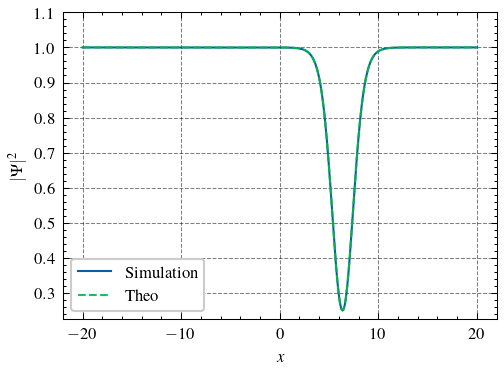

In [7]:
path = "Examples/Gif/"
w_comp.animate_solution(path+"dark_D1.gif", 50, auto_adjust=False, theo=True)

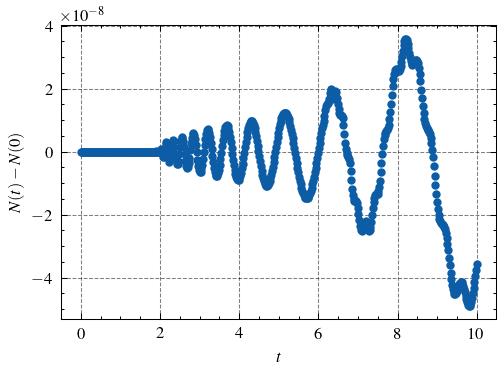

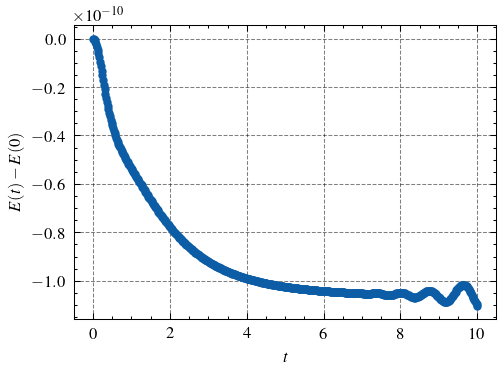

In [8]:
w_mass = w_comp.get_mass(plot=True)
w_energy = w_comp.get_energy(plot=True)

# Dark solitons in $D_2$

In [13]:
# Create solitons
L = 100
N = 10_001

k = -50
pars = {"k":k}
c_0 = np.sqrt(2)/2

P_p_ = lambda c: P_p(c, k)
P_pp_ = lambda c: P_pp(c, k)

c_star, error = newton_1D(c_0, P_p_, P_pp_)

eps = 0.1
c = c_star + eps

# The0retical solitons
w_dark_D2, x_dark = soliton(c, k, soliton_type="dark", L=L, N=N, as_func=True) #c=0

Creating soliton...
Soliton created


In [14]:
def theo_dark_D2(x, t):
    output = w_dark_D2(x - c*t)
    return output

In [15]:
#path = "test/"
Nt = 500
tf = 10

w_D2 = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_D2.set_w_theo(theo_dark_D2)
w_D2.solve()

Iteration  1  of  500 . Newton Error:  4.6625973928111265e-15 . Total iteration:  4
Iteration  2  of  500 . Newton Error:  3.691646562329132e-15 . Total iteration:  4
Iteration  3  of  500 . Newton Error:  3.595504440470893e-15 . Total iteration:  4
Iteration  4  of  500 . Newton Error:  3.508553710122521e-15 . Total iteration:  4
Iteration  5  of  500 . Newton Error:  3.5717388626729796e-15 . Total iteration:  4
Iteration  6  of  500 . Newton Error:  2.460658141653368e-15 . Total iteration:  4
Iteration  7  of  500 . Newton Error:  6.432182230541023e-15 . Total iteration:  4
Iteration  8  of  500 . Newton Error:  3.468941005720477e-15 . Total iteration:  4
Iteration  9  of  500 . Newton Error:  3.853600405804462e-15 . Total iteration:  4
Iteration  10  of  500 . Newton Error:  3.867613906641009e-15 . Total iteration:  4
Iteration  11  of  500 . Newton Error:  2.640452447996812e-15 . Total iteration:  4
Iteration  12  of  500 . Newton Error:  2.2546111557288065e-15 . Total iteration:  

MovieWriter ffmpeg unavailable; using Pillow instead.


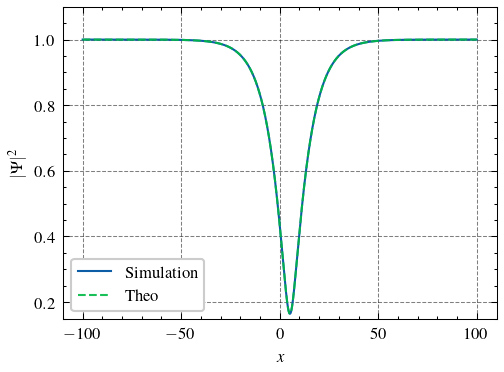

In [16]:
path = "Examples/Gif/"
w_D2.animate_solution(path+"dark_D2.gif", 50, auto_adjust=False, theo=True)

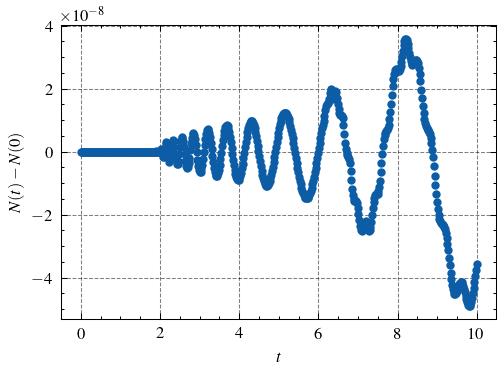

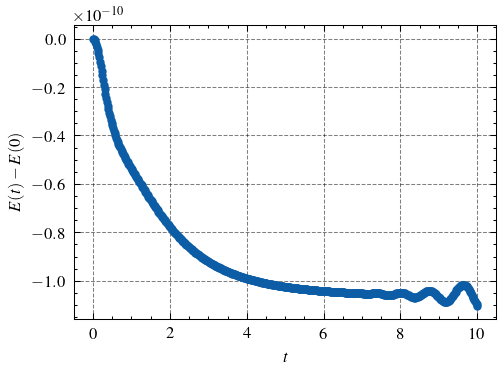

In [8]:
w_mass = w_comp.get_mass(plot=True)
w_energy = w_comp.get_energy(plot=True)